17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training RNN
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 117ms/step - accuracy: 0.6462 - loss: 0.6220 - val_accuracy: 0.8000 - val_loss: 0.4463
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 103ms/step - accuracy: 0.8002 - loss: 0.4422 - val_accuracy: 0.8180 - val_loss: 0.4202
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 118ms/step - accuracy: 0.9024 - loss: 0.2491 - val_accuracy: 0.8266 - val_loss: 0.4361
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step

Training LSTM
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 62s 379ms/step - accuracy: 0.7531 - loss: 0.4837 - val_accuracy: 0.8524 - val_loss: 0.3520
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 342ms/step - accuracy: 0.8853 - loss: 0.2866 - val_accuracy: 0.8296 - val_loss: 0.4052
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 348ms/step - accuracy: 0.9158 - loss: 0.2246 - val_accuracy: 0.8642 - val_loss: 0.3260
782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step

Training GRU
Epoch 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 413ms/step - accuracy: 0.7413 - loss: 0.4957 - val_accuracy: 0.8352 - val_loss: 0.3667
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 66s 419ms/step - accuracy: 0.8915 - loss: 0.2687 - val_accuracy: 0.8720 - val_loss: 0.3096
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 65s 412ms/step - accuracy: 0.9270 - loss: 0.1962 - val_accuracy: 0.8380 - val_loss: 0.3737
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step

Model Performance Comparison:
  Model  Accuracy  Precision   Recall  F1-Score
0   RNN   0.82892   0.828526  0.82952  0.829023
1  LSTM   0.86104   0.840244  0.89160  0.865161
2   GRU   0.83856   0.809312  0.88584  0.845848


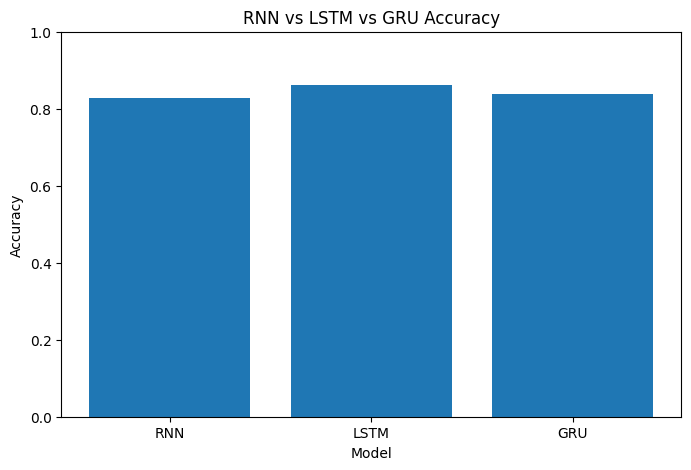

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Parameters
vocab_size = 10000
max_length = 200

# Load IMDb dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

# Padding sequences
x_train = pad_sequences(x_train, maxlen=max_length)
x_test = pad_sequences(x_test, maxlen=max_length)

# Function to create model
def create_model(model_type):
    model = Sequential()
    model.add(Embedding(vocab_size, 64, input_length=max_length))

    if model_type == "RNN":
        model.add(SimpleRNN(64))
    elif model_type == "LSTM":
        model.add(LSTM(64))
    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

results = []

# Train and evaluate models
for model_type in ["RNN", "LSTM", "GRU"]:

    print("\nTraining", model_type)

    model = create_model(model_type)

    history = model.fit(
        x_train, y_train,
        epochs=3,
        batch_size=128,
        validation_split=0.2,
        verbose=1
    )

    y_prob = model.predict(x_test)
    y_pred = (y_prob > 0.5).astype(int).flatten()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append([
        model_type,
        accuracy,
        precision,
        recall,
        f1
    ])

# Comparison table
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"]
)

print("\nModel Performance Comparison:")
print(results_df)

# Plot accuracy comparison
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("RNN vs LSTM vs GRU Accuracy")
plt.ylim(0, 1)
plt.show()